# Milestone 3 - Task 4: Train and Evaluate K-Nearest Neighbors

## Objective

This analysis trains and evaluates a K-Nearest Neighbors (KNN) classification model to predict whether a Kickstarter campaign will succeed or fail.

The analysis uses the shared feature selection and preprocessing approach established in Milestone 3 Task 1.

The goals are to:
- Prepare and scale the selected campaign features.
- Train KNN models using different values of K.
- Identify the best-performing KNN model.
- Evaluate model performance using classification metrics.
- Document key findings and limitations.


In [1]:
import pandas as pd
import numpy as np

# Load the U.S.-filtered Kickstarter dataset
df = pd.read_csv("../data/kickstarter_us_filtered.csv")

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (38504, 17)


,project id,name,url,category,subcategory,location,status,goal,pledged,funded percentage,backers,funded date,levels,reward levels,updates,comments,duration
0,39409,WHILE THE TREES SLEEP,http://www.kickstarter.com/projects/emiliesaba...,Film & Video,Short Film,"Columbia, MO",successful,10500.0,11545.0,1.099524,66,"Fri, 19 Aug 2011 19:28:17 -0000",7,"$25,$50,$100,$250,$500,$1,000,$2,500",10,2,30.00
1,126581,Educational Online Trading Card Game,http://www.kickstarter.com/projects/972789543/...,Games,Board & Card Games,"Maplewood, NJ",failed,4000.0,20.0,0.005000,2,"Mon, 02 Aug 2010 03:59:00 -0000",5,"$1,$5,$10,$25,$50",6,0,47.18
2,237090,GETTING OVER - One son's search to finally kno...,http://www.kickstarter.com/projects/charnick/g...,Film & Video,Documentary,"Los Angeles, CA",successful,6000.0,6535.0,1.089167,100,"Sun, 08 Apr 2012 02:14:00 -0000",13,"$1,$10,$25,$30,$50,$75,$85,$100,$110,$250,$500...",4,0,32.22
3,246101,The Launch of FlyeGrlRoyalty &quot;The New Nam...,http://www.kickstarter.com/projects/flyegrlroy...,Fashion,Fashion,"Novi, MI",failed,3500.0,0.0,0.000000,0,"Wed, 01 Jun 2011 15:25:39 -0000",6,"$10,$25,$50,$100,$150,$250",2,0,30.00
4,316217,Dinner Party - a short film about friendship.....,http://www.kickstarter.com/projects/249354515/...,Film & Video,Short Film,"Portland, OR",successful,3500.0,3582.0,1.023331,39,"Wed, 22 Jun 2011 13:33:00 -0000",7,"$5,$25,$50,$100,$250,$500,$1,000",8,0,21.43


In [2]:
# Convert campaign status into a binary target variable
# 1 = successful campaign, 0 = failed campaign

df["success"] = (df["status"] == "successful").astype(int)

print("Campaign outcomes:")
print(df["success"].value_counts())

print("\nSuccess rate:")
print(round(df["success"].mean() * 100, 2), "%")

Campaign outcomes:
success
1    21075
0    17429
Name: count, dtype: int64

Success rate:
54.73 %


In [3]:
# Extract the state from the campaign location
df["state"] = (
    df["location"]
    .str.rsplit(",", n=1)
    .str[-1]
    .str.strip()
)

# Define the features used for prediction
numerical_features = ["goal", "duration", "levels"]
categorical_features = ["category", "subcategory", "state"]

selected_features = numerical_features + categorical_features

# Separate the input features from the target variable
X = df[selected_features].copy()
y = df["success"].copy()

# Check the selected features
print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)

print("\nMissing values:")
print(X.isnull().sum())

X.head()

Feature matrix shape: (38504, 6)
Target shape: (38504,)

Missing values:
goal           0
duration       0
levels         0
category       0
subcategory    0
state          0
dtype: int64


,goal,duration,levels,category,subcategory,state
0,10500.0,30.00,7,Film & Video,Short Film,MO
1,4000.0,47.18,5,Games,Board & Card Games,NJ
2,6000.0,32.22,13,Film & Video,Documentary,CA
3,3500.0,30.00,6,Fashion,Fashion,MI
4,3500.0,21.43,7,Film & Video,Short Film,OR


In [4]:
from sklearn.model_selection import train_test_split

# Split the dataset into training and testing sets
# 80% training, 20% testing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Check the sizes of the training and testing sets
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

print("\nTraining success rate:")
print(y_train.value_counts(normalize=True))

print("\nTesting success rate:")
print(y_test.value_counts(normalize=True))

Training rows: 30803
Testing rows: 7701

Training success rate:
success
1    0.547349
0    0.452651
Name: proportion, dtype: float64

Testing success rate:
success
1    0.547332
0    0.452668
Name: proportion, dtype: float64


## Feature Preprocessing

KNN is a distance-based classification algorithm, so feature scaling is important to prevent variables with larger numerical values from dominating the distance calculations.

Following the preprocessing approach established in Milestone 3 Task 1:
- Numerical features (`goal`, `duration`, and `levels`) are standardized using `StandardScaler`.
- Categorical features (`category`, `subcategory`, and `state`) are converted into numerical representations using `OneHotEncoder`.
- The preprocessing steps will be combined with KNN in a pipeline to ensure transformations are learned from training data only.

In [5]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier

# Standardize numerical features
numeric_transformer = StandardScaler()

# Encode categorical features
categorical_transformer = OneHotEncoder(handle_unknown="ignore")

# Combine numerical and categorical preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numerical_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

# Check the preprocessing setup
print("Numerical features:", numerical_features)
print("Categorical features:", categorical_features)
print("\nPreprocessor created successfully!")

Numerical features: ['goal', 'duration', 'levels']
Categorical features: ['category', 'subcategory', 'state']

Preprocessor created successfully!


## K-Nearest Neighbors Model Training

K-Nearest Neighbors (KNN) is a supervised machine learning algorithm that classifies new observations based on the outcomes of similar observations in the training dataset.

For this analysis, an initial KNN model is trained using K = 5. This provides a starting point before comparing different values of K to identify the best-performing model.

The model uses a pipeline that combines feature preprocessing with KNN classification, ensuring that numerical scaling and categorical encoding are applied consistently.

In [6]:
knn_pipeline = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=5))
    ]
)

# Train the KNN model
knn_pipeline.fit(X_train, y_train)

# Check that training completed
print("KNN model trained successfully!")
print("Number of neighbors (K):", knn_pipeline.named_steps["classifier"].n_neighbors)
print("Training samples:", len(X_train))

KNN model trained successfully!
Number of neighbors (K): 5
Training samples: 30803


## Comparing Different K Values

To identify the best-performing KNN model, several values of K are evaluated using 5-fold stratified cross-validation.

The models are compared using the F1-score, which balances precision and recall. This is useful because the dataset contains both successful and failed campaigns, with a slightly higher proportion of successful campaigns.

Cross-validation is performed using only the training data to avoid using the test set during model selection.

In [7]:
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.base import clone

# Different values of K to compare
k_values = [3, 5, 7, 9, 11]

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

knn_results = []

for k in k_values:
    # Create a fresh copy of the preprocessing pipeline
    model = clone(knn_pipeline)
    model.set_params(classifier__n_neighbors=k)

    # Evaluate using F1-score
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=-1
    )

    knn_results.append({
        "K": k,
        "Mean F1": scores.mean(),
        "Std F1": scores.std()
    })
    
results_df = pd.DataFrame(knn_results)

print("KNN Cross-Validation Results:")
print(results_df.round(4))

Python(66180) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


KNN Cross-Validation Results:
    K  Mean F1  Std F1
0   3   0.6508  0.0052
1   5   0.6650  0.0061
2   7   0.6769  0.0064
3   9   0.6827  0.0084
4  11   0.6894  0.0075


## Initial Cross-Validation Findings

The initial comparison tested K values of 3, 5, 7, 9, and 11 using 5-fold stratified cross-validation.

The mean F1-score increased as K increased, with K = 11 achieving the highest score of 0.6894. The standard deviations were relatively small across the tested values.

Since performance was still improving at K = 11, additional values will be evaluated before selecting the final model.

In [8]:
# Test additional K values
additional_k_values = [15, 21, 31, 41]

additional_results = []

for k in additional_k_values:
    model = clone(knn_pipeline)
    model.set_params(classifier__n_neighbors=k)

    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1",
        n_jobs=-1
    )

    additional_results.append({
        "K": k,
        "Mean F1": scores.mean(),
        "Std F1": scores.std()
    })

additional_df = pd.DataFrame(additional_results)

all_results_df = pd.concat(
    [results_df, additional_df],
    ignore_index=True
).sort_values("K")

print("Updated KNN Cross-Validation Results:")
print(all_results_df.round(4))

Updated KNN Cross-Validation Results:
    K  Mean F1  Std F1
0   3   0.6508  0.0052
1   5   0.6650  0.0061
2   7   0.6769  0.0064
3   9   0.6827  0.0084
4  11   0.6894  0.0075
5  15   0.6967  0.0062
6  21   0.7020  0.0052
7  31   0.7070  0.0050
8  41   0.7078  0.0047


## KNN Hyperparameter Tuning Results

Nine values of K were evaluated using 5-fold stratified cross-validation on the training dataset.

The mean F1-score generally improved as K increased. Among the tested values, K = 41 achieved the highest mean F1-score of 0.7078, with a standard deviation of 0.0047.

The improvement between K = 31 and K = 41 was relatively small, suggesting that model performance may be beginning to stabilize.

Based on these results, K = 41 was selected as the best-performing value among those evaluated.

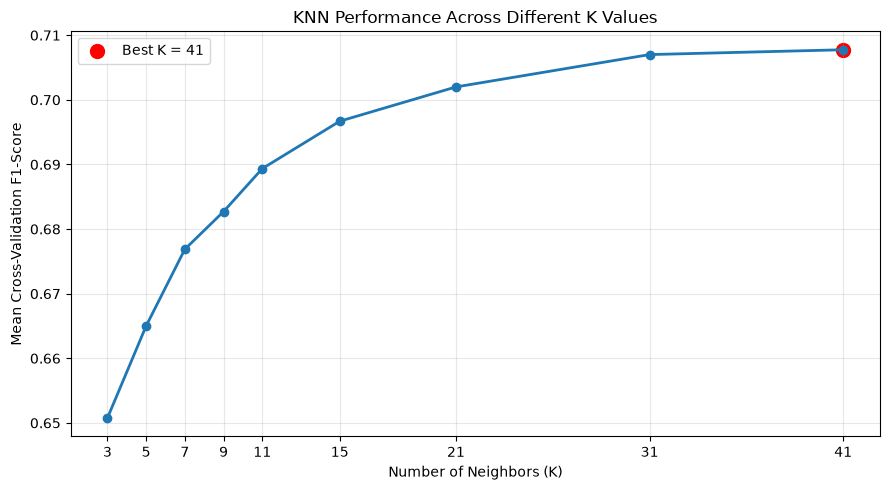

Selected K: 41
Best Cross-Validation F1: 0.7078


In [9]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.plot(
    all_results_df["K"],
    all_results_df["Mean F1"],
    marker="o",
    linewidth=2
)

# Highlight the best K value
best_row = all_results_df.loc[all_results_df["Mean F1"].idxmax()]
best_k = int(best_row["K"])

plt.scatter(
    best_k,
    best_row["Mean F1"],
    color="red",
    s=100,
    label=f"Best K = {best_k}"
)

plt.title("KNN Performance Across Different K Values")
plt.xlabel("Number of Neighbors (K)")
plt.ylabel("Mean Cross-Validation F1-Score")
plt.xticks(all_results_df["K"])
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

print("Selected K:", best_k)
print("Best Cross-Validation F1:", round(best_row["Mean F1"], 4))

## Final KNN Model Training

Based on the cross-validation results, K = 41 was selected as the best-performing value among the nine values tested.

The final KNN model is trained using the complete training dataset, which contains 30,803 campaigns.

The preprocessing and classification steps are combined in a pipeline to ensure consistent feature transformations. The testing dataset remains separate and will be used to evaluate the model's performance on unseen campaigns.

In [10]:
# Create the final KNN model using the best K value
final_knn_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("classifier", KNeighborsClassifier(n_neighbors=best_k))
    ]
)

final_knn_model.fit(X_train, y_train)

print("Final KNN model trained successfully!")
print("Selected K:", best_k)
print("Training samples:", len(X_train))
print("Testing samples reserved:", len(X_test))

Final KNN model trained successfully!
Selected K: 41
Training samples: 30803
Testing samples reserved: 7701


## Final KNN Model Evaluation

The final KNN model, using K = 41, is evaluated on the reserved testing dataset containing 7,701 Kickstarter campaigns.

The model's performance is measured using accuracy, precision, recall, F1-score, and ROC-AUC. These metrics provide a more complete understanding of how effectively the model predicts campaign success.

The test dataset was not used during hyperparameter tuning, allowing the final evaluation to measure performance on previously unseen data.

**ROC-AUC:** This metric measures how well the model separates successful campaigns from failed campaigns across classification thresholds. It is calculated from the predicted probability of success, not just the final class predictions.

In [11]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Make predictions on the testing dataset
y_pred = final_knn_model.predict(X_test)

# Get predicted probabilities for the positive class (successful campaign).
# ROC-AUC uses probabilities rather than the binary class predictions.
y_pred_proba = final_knn_model.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_pred_proba)

# Display results
print("Final KNN Model Evaluation")
print("--------------------------")
print("Selected K:", best_k)
print("Accuracy:", round(accuracy, 4))
print("Precision:", round(precision, 4))
print("Recall:", round(recall, 4))
print("F1-score:", round(f1, 4))
print("ROC-AUC:", round(roc_auc, 4))

Final KNN Model Evaluation
--------------------------
Selected K: 41
Accuracy: 0.652
Precision: 0.6567
Recall: 0.763
F1-score: 0.7059
ROC-AUC: 0.705


## Final Model Evaluation Results

The final KNN model was evaluated on 7,701 previously unseen Kickstarter campaigns using K = 41.

The model achieved the following results:

- Accuracy: 0.6520 (65.20%)
- Precision: 0.6567 (65.67%)
- Recall: 0.7630 (76.30%)
- F1-score: 0.7059 (70.59%)
- ROC-AUC: 0.7049 (70.49%)

The model demonstrated relatively strong recall, correctly identifying approximately 76% of successful campaigns. However, its lower precision indicates that some campaigns predicted to succeed were unsuccessful.

The final test F1-score of 0.7059 was close to the cross-validation F1-score of 0.7078, suggesting consistent performance on unseen data.

The ROC-AUC of about 0.70 means the model ranks a randomly chosen successful campaign above a randomly chosen failed one roughly 70% of the time. This is better than random guessing (0.50) but only moderate separation between the two classes.

These results provide a basis for comparing KNN against other classification models developed during Milestone 3.

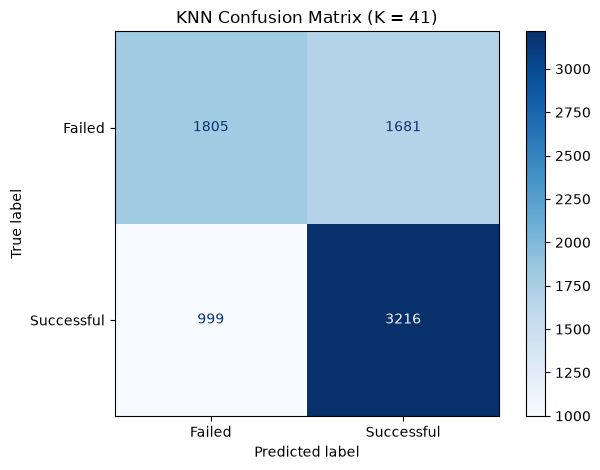

True Negatives: 1805
False Positives: 1681
False Negatives: 999
True Positives: 3216


In [12]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Failed", "Successful"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("KNN Confusion Matrix (K = 41)")
plt.tight_layout()
plt.show()

tn, fp, fn, tp = cm.ravel()

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)

## Confusion Matrix Analysis

The confusion matrix provides a breakdown of the final KNN model's predictions on the 7,701 testing campaigns.

The results were:

- True Negatives: 1,805
- False Positives: 1,681
- False Negatives: 999
- True Positives: 3,216

The model correctly identified 3,216 successful campaigns and 1,805 failed campaigns.

The model demonstrated stronger performance in identifying successful campaigns, achieving a recall of 76.30%. However, it incorrectly classified 1,681 failed campaigns as successful.

This suggests that while KNN can identify many campaigns that eventually succeed, it also produces a considerable number of false-positive predictions.

For a crowdfunding recommendation system, this is an important limitation because recommending campaigns that are unlikely to succeed could reduce the reliability of the recommendations.

## Conclusion

This analysis trained and evaluated a K-Nearest Neighbors (KNN) classification model to predict the success of Kickstarter crowdfunding campaigns.

The model used six features: goal, duration, levels, category, subcategory, and state. Numerical features were standardized, while categorical features were one-hot encoded.

Nine values of K were compared using 5-fold stratified cross-validation. Among the tested values, K = 41 achieved the highest mean F1-score of 0.7078 and was selected for the final model.

The final model achieved the following performance on the testing dataset:

- Accuracy: 65.20%
- Precision: 65.67%
- Recall: 76.30%
- F1-score: 70.59%
- ROC-AUC: 70.49%

The model demonstrated relatively strong recall for successful campaigns, although its precision, overall accuracy, and ROC-AUC indicate room for improvement.

Although KNN demonstrated consistent performance across cross-validation and testing, prediction required additional computational time due to the algorithm's distance-based approach. This highlights an important consideration when comparing KNN with other models for the recommendation engine.

Overall, KNN provides a useful classification approach for predicting Kickstarter campaign success. Its performance can be compared against Logistic Regression, Random Forest, and other models developed during Milestone 3 to determine which algorithm is most suitable for the recommendation engine.